In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "TousAge_allergie_urgences"
EXOS  = ['As in PM10', 'BaP in PM10', 'Cd in PM10',
       'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
       'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1',
       'pression_mer', 'tendance_pression_3h', 
       'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite',
       'pression_station', 'precipitation_3h', 'tp_averses_ou_orages',
       'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers',
       'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure',
       'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
       'tp_tempete_poussiere_chasse_neige', 'TousAge_asthme_urgences', 'TousAge_asthme_hospitalisation', 
       '0an_bronchiolite_urgences', 'TousAge_allergie_hospitalisation', 
       'prev_calc_Maladie_Respi_Chronique_0-14_9',
       'prev_calc_Maladie_Respi_Chronique_15-64_9',
       'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain',
       'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes',
       'pct_ouvriers', 'pct_retraites', 
       'pct_agriculteurs', 'densite_generalistes', 'densite_pediatres',
       'densite_pneumologues', 'densite_allergologues', 'densite_kines',
       'sos_present']

H     = 1                                   # nombre de semaines futures moyennées

# --- Une ligne par département et par semaine t : cible = moyenne de y(t+1)..y(t+H) ---
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y, sem = d[CIBLE], d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean()          # moyenne de y(t-H+1)..y(t), NaN si un trou
    morceaux.append(pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),      # première semaine de la fenêtre cible
        "date_fin":   d.index + pd.Timedelta(weeks=H),      # dernière semaine de la fenêtre cible
        "cible":      moy_glis.shift(-H),                   # moyenne de y(t+1)..y(t+H)
        "y_passe":    moy_glis,                             # moyenne des H dernières semaines connues
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem_sin": np.sin(2 * np.pi * sem / 52.18),
        "sem_cos": np.cos(2 * np.pi * sem / 52.18),
        **{c: d[c] for c in EXOS},
    }))
panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])

# --- Split sur l'année de la DERNIÈRE semaine de la fenêtre (pas de chevauchement train/val) ---
an = panel["date_fin"].dt.year
panel["split"] = np.select([an <= 2022, an == 2023], ["train", "val"], default="test")

# --- Baselines sur la même cible agrégée ---
# 1) persistance : la moyenne des H semaines à venir vaut celle des H semaines passées
panel["base_persist"] = panel["y_passe"]
# 2) profil saisonnier : moyenne de la cible sur le train, par département et semaine de début
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = (panel[panel["split"] == "train"]
          .groupby(["code_dept", "sem_debut"])["cible"].mean().rename("base_saison"))
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil sais.:", scores(val["cible"], val["base_saison"]))

split
train    9696
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.10406010438441571, 'MAE': 219.0278099115345, 'RMSE': 306.1079964711084}
Profil sais.: {'R2': 0.24309945964229396, 'MAE': 204.9145384364762, 'RMSE': 281.3550045842997}


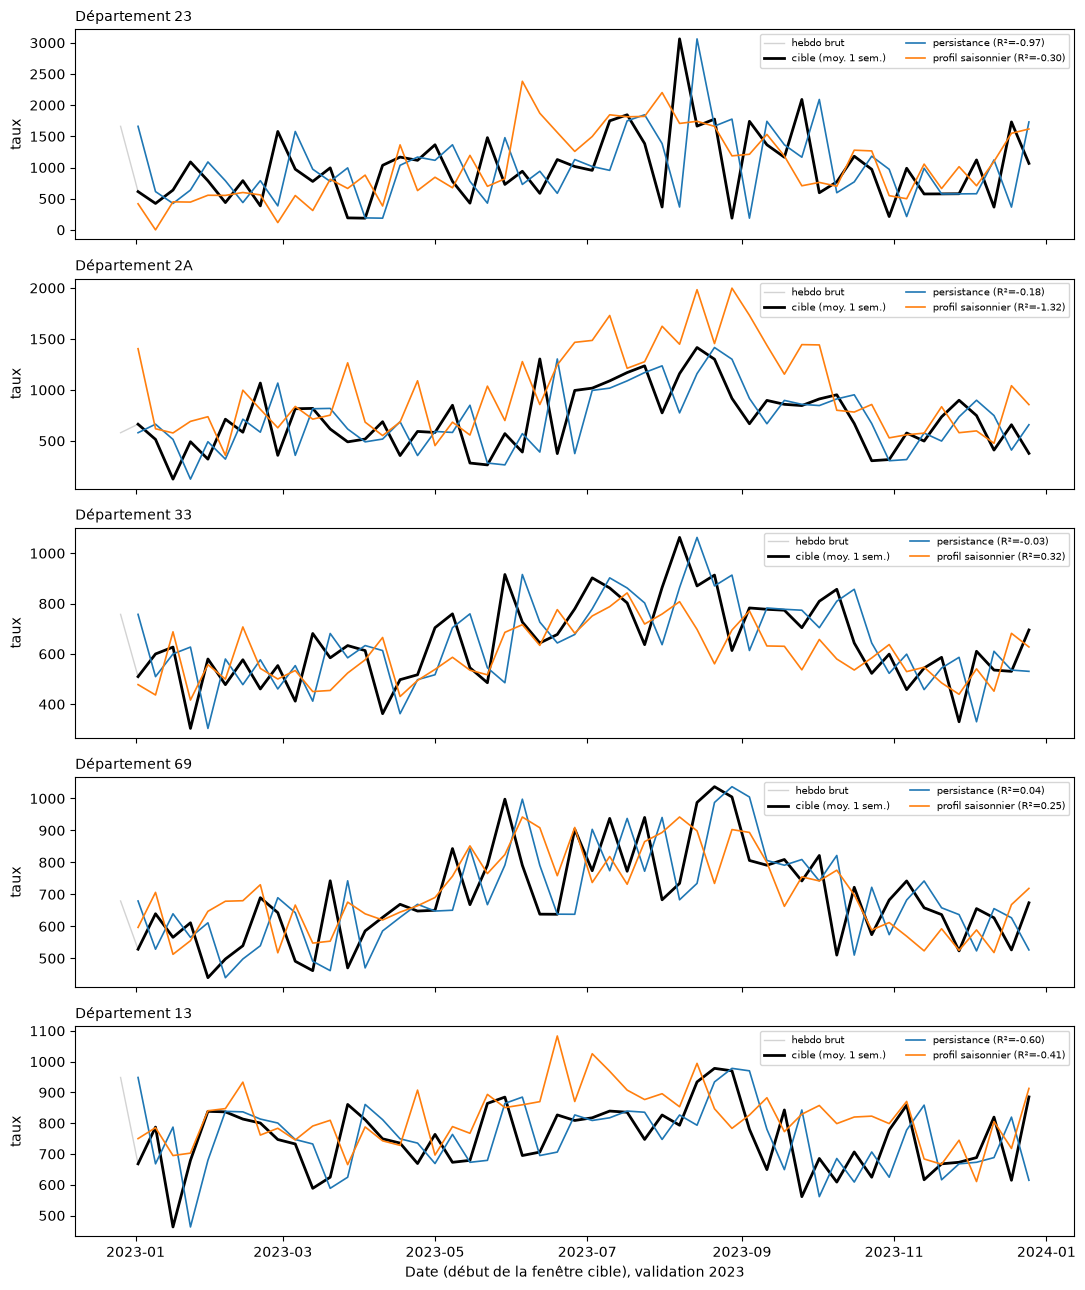

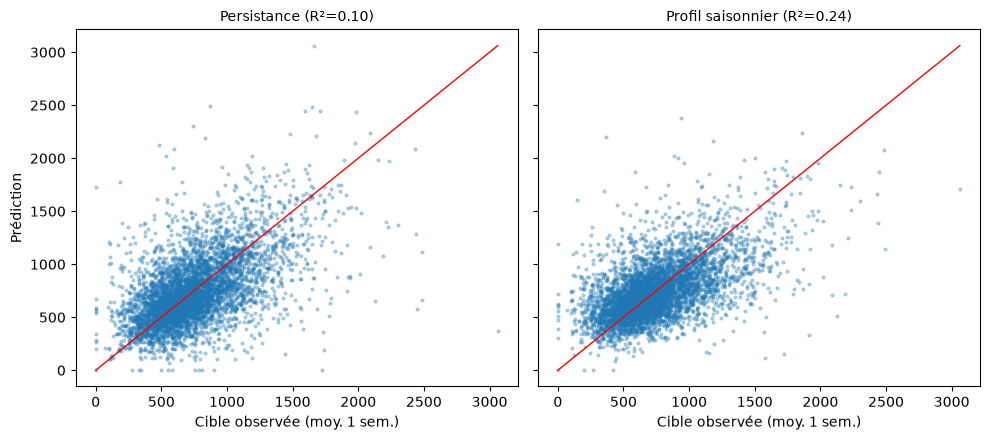

In [35]:
DEPTS = ["23", "2A", "33", "69", "13"]          # départements à afficher

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]
    # valeur hebdomadaire brute de la semaine t (y_lag0), placée à sa propre date
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)                 # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

#FEATURES = ["profil", "y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos", "code_dept"] + EXOS

FEATURES = ["y_lag0", "y_lag1", "y_lag2", "sem_sin", "sem_cos"] + EXOS
CAT = []
NUM = [c for c in FEATURES if c not in CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
])
modele = Pipeline([("prep", prep), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.4472944521025196, 'MAE': 174.9416885034418, 'RMSE': 238.9508195539749}


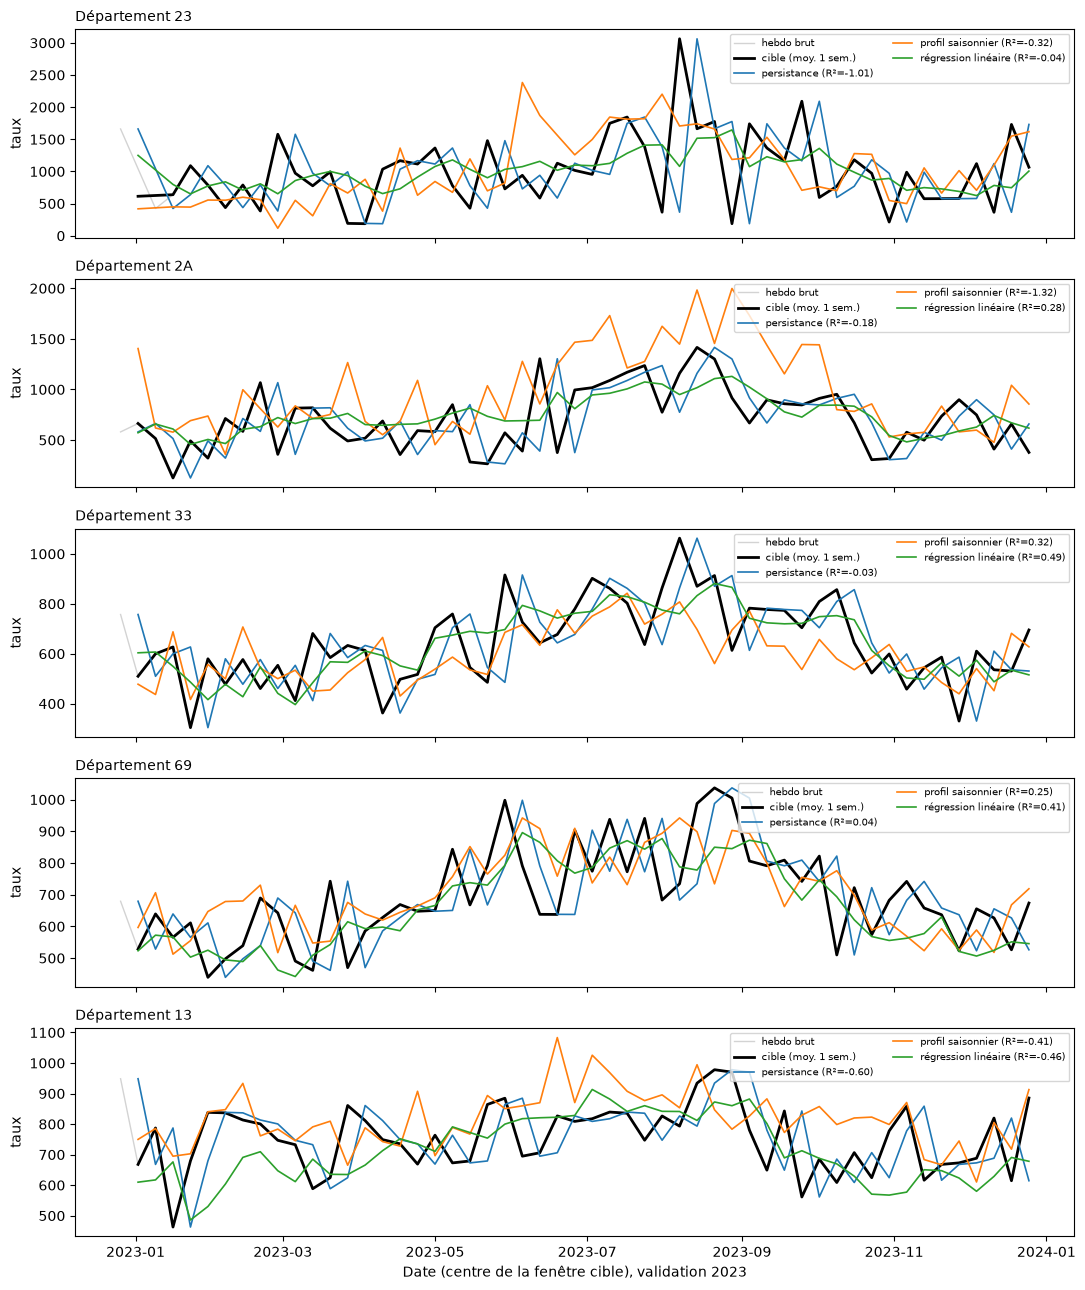

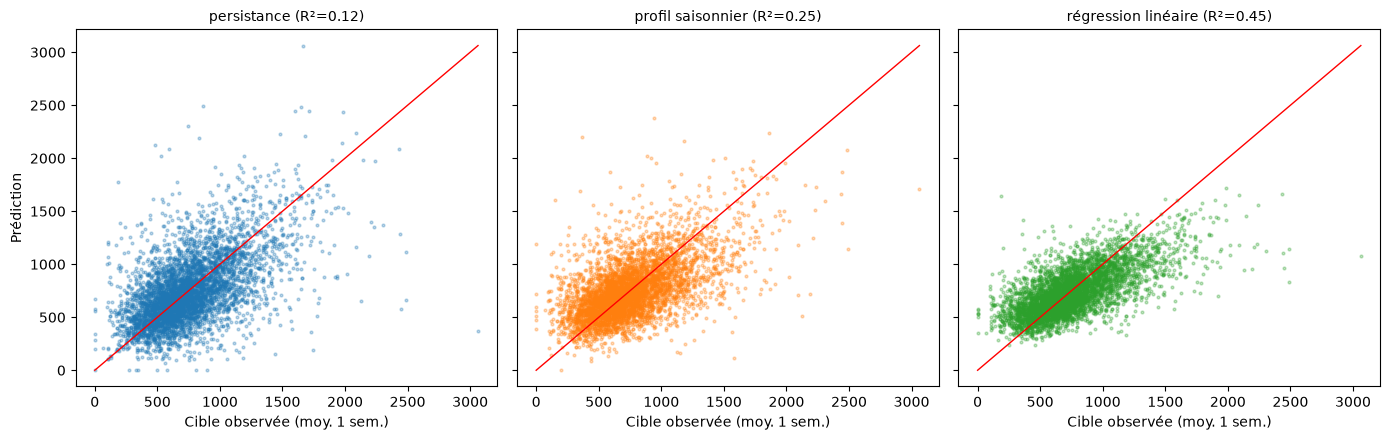

In [37]:
import matplotlib.pyplot as plt

# Prédictions du modèle sur la validation, mêmes lignes que les baselines
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison",  "profil saisonnier", "tab:orange"),
          ("pred_LR",      "régression linéaire", "tab:green")]

# --- Séries temporelles par département ---
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# --- Vue d'ensemble, tous départements : prédit vs observé ---
fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
lim = [0, v_all[["cible"] + [c for c, _, _ in SERIES]].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1)                   # diagonale y = x
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

Silhouette : {2: 0.389, 3: 0.378, 4: 0.373, 5: 0.39, 6: 0.405} -> k = 6
         r2_persist  r2_saison  n_dept
cluster                               
0             -0.54      -0.88      19
1             -0.18      -0.46      38
2              0.24      -1.16       8
3             -0.18      -1.96       9
4              0.40      -4.14       1
5              0.17      -0.26      21


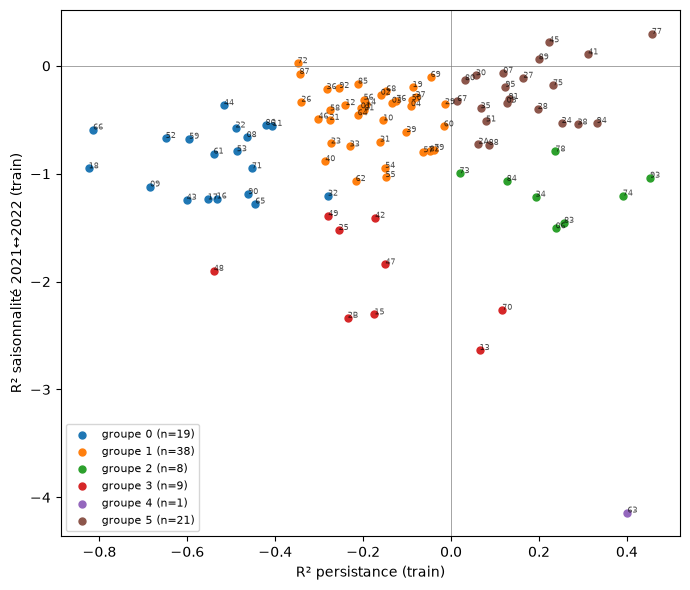

       persistance  profil  LR globale  LR par groupe
0            0.008   0.198       0.400          0.396
1            0.128   0.281       0.445          0.451
2            0.215   0.224       0.446          0.389
3           -0.459  -0.313       0.148         -0.139
4           -0.453  -0.250       0.364         -0.030
5            0.327   0.381       0.548          0.563
TOTAL        0.120   0.250       0.447          0.426


In [38]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# --- 1) Indicateurs par département, sur le train uniquement (valeur hebdo brute y_lag0 en t) ---
brut = panel.loc[panel["split"] == "train", ["code_dept", "y_lag0"]].copy()
iso = brut.index.isocalendar()
brut["an"], brut["sem"] = iso.year.values, iso.week.values

def indicateurs(d):
    # Persistance : y(t) prédit par y(t-1)
    y = d.sort_index()["y_lag0"]
    paire = pd.concat([y.shift(1), y], axis=1, keys=["prec", "act"]).dropna()
    r2_persist = r2_score(paire["act"], paire["prec"])
    # Saisonnalité : 2022 prédit par 2021, 2021 prédit par 2022, moyenne des deux R²
    piv = d.pivot_table(index="sem", columns="an", values="y_lag0")
    if not {2021, 2022} <= set(piv.columns):
        return pd.Series({"r2_persist": r2_persist, "r2_saison": np.nan})
    a = piv[[2021, 2022]].dropna()                     # semaines présentes les deux années
    r2_saison = (r2_score(a[2022], a[2021]) + r2_score(a[2021], a[2022])) / 2
    return pd.Series({"r2_persist": r2_persist, "r2_saison": r2_saison})

ind = brut.groupby("code_dept").apply(indicateurs).dropna()

# --- 2) KMeans sur les deux indicateurs, nombre de groupes choisi par silhouette ---
X = StandardScaler().fit_transform(ind[["r2_persist", "r2_saison"]])
sil = {k: silhouette_score(X, KMeans(k, n_init=20, random_state=0).fit_predict(X)) for k in range(2, 7)}
k_opt = max(sil, key=sil.get)
ind["cluster"] = KMeans(k_opt, n_init=20, random_state=0).fit_predict(X)
print("Silhouette :", {k: round(v, 3) for k, v in sil.items()}, "-> k =", k_opt)
print(ind.groupby("cluster")[["r2_persist", "r2_saison"]].mean().round(2)
         .assign(n_dept=ind["cluster"].value_counts().sort_index()))

fig, ax = plt.subplots(figsize=(7, 6))
for k, g in ind.groupby("cluster"):
    ax.scatter(g["r2_persist"], g["r2_saison"], s=25, label=f"groupe {k} (n={len(g)})")
    for dept, r in g.iterrows():
        ax.annotate(dept, (r["r2_persist"], r["r2_saison"]), fontsize=6, alpha=0.7)
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("R² persistance (train)"); ax.set_ylabel("R² saisonnalité 2021↔2022 (train)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# --- 3) Modèle global vs un modèle par groupe, mêmes lignes de validation ---
panel = panel.drop(columns="cluster", errors="ignore").join(ind["cluster"], on="code_dept")
train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible", "cluster"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible", "cluster", "base_saison"]).copy()

val_m["pred_global"] = clone(modele).fit(train[FEATURES], train["cible"]).predict(val_m[FEATURES])
val_m["pred_groupe"] = np.nan
for k, tr_k in train.groupby("cluster"):
    m_k = clone(modele).fit(tr_k[FEATURES], tr_k["cible"])
    sel = (val_m["cluster"] == k).values
    val_m.loc[sel, "pred_groupe"] = m_k.predict(val_m.loc[sel, FEATURES])

# --- 4) R² par groupe et au total ---
cols = {"persistance": "base_persist", "profil": "base_saison",
        "LR globale": "pred_global", "LR par groupe": "pred_groupe"}
res = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in val_m.groupby("cluster")}
res["TOTAL"] = {nom: scores(val_m["cible"], val_m[c])["R2"] for nom, c in cols.items()}
print(pd.DataFrame(res).T.round(3))

Départements avec NaN dans les variables actives : []
Variance expliquée (%) : [31.5 16.3 13.8  8.6  6.4  5.3]

Variables actives :
                                             CP1   CP2   CP3
pct_retraites                             -0.81  0.49 -0.09
pct_agriculteurs                          -0.71  0.38 -0.21
pct_ouvriers                              -0.67 -0.46  0.04
prev_calc_Maladie_Respi_Chronique_15-64_9 -0.48 -0.04  0.80
prev_calc_Maladie_Respi_Chronique_65+_9   -0.14 -0.12  0.87
pct_artisans                              -0.00  0.79 -0.12
pct_employes                               0.05 -0.26  0.50
prev_calc_Maladie_Respi_Chronique_0-14_9   0.07  0.27  0.58
densite_generalistes                       0.32  0.68  0.09
densite_pneumologues                       0.41  0.31  0.48
densite_kines                              0.44  0.79  0.10
sos_present                                0.44 -0.15  0.11
densite_allergologues                      0.45  0.07  0.02
pct_prof_inter             

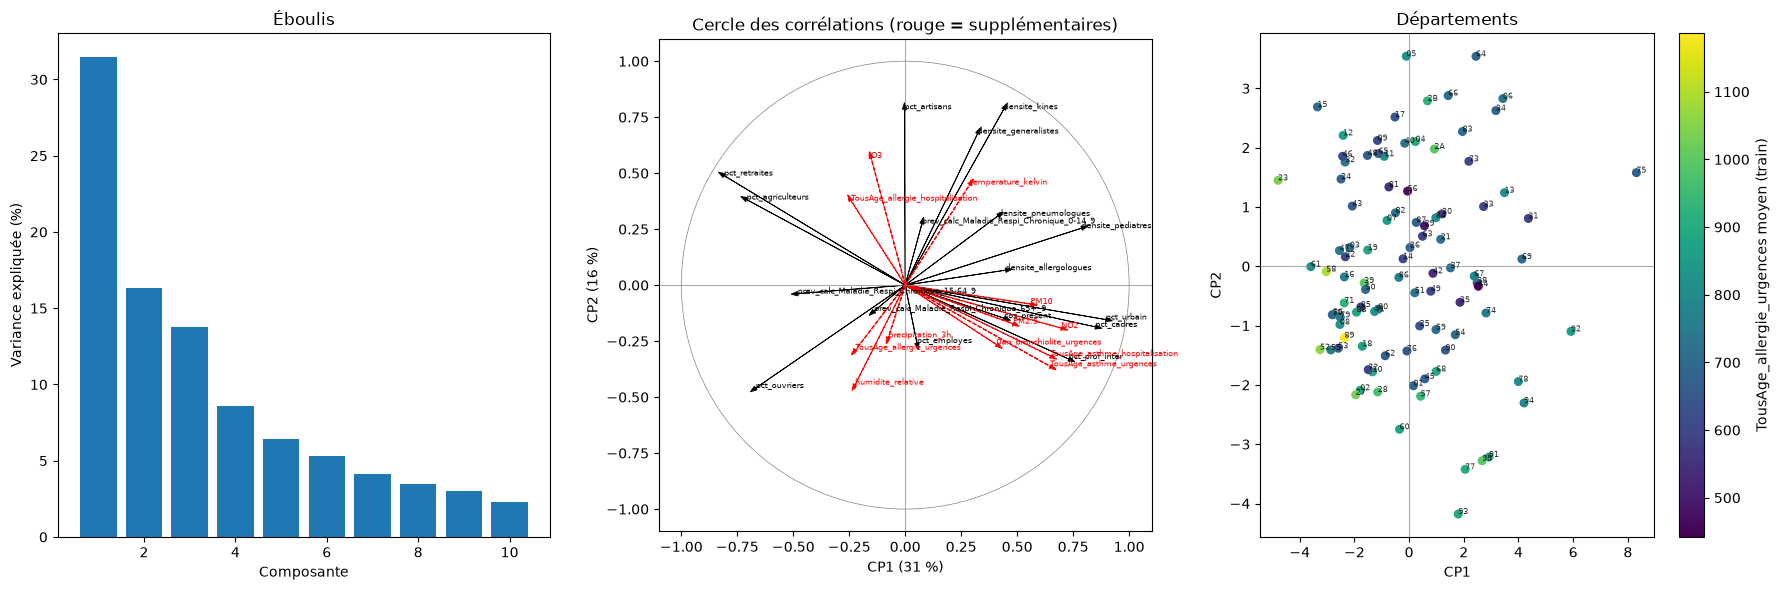

In [39]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- 1) Table départementale : moyennes sur le train uniquement ---
IDENTITE = [c for c in EXOS if c.startswith(("pct_", "prev_calc_", "densite_"))] + ["sos_present"]
SUPPL = ["temperature_kelvin", "humidite_relative", "precipitation_3h",
         "NO2", "O3", "PM10", "PM2.5",
         "TousAge_asthme_urgences", "TousAge_asthme_hospitalisation",
         "0an_bronchiolite_urgences", "TousAge_allergie_hospitalisation"]

tr = panel[panel["split"] == "train"]
dep = (tr.groupby("code_dept")[IDENTITE + SUPPL + ["y_lag0"]].mean()
         .rename(columns={"y_lag0": CIBLE}))                 # y_lag0 = taux brut de la semaine t
print("Départements avec NaN dans les variables actives :",
      dep.index[dep[IDENTITE].isna().any(axis=1)].tolist())
dep = dep.dropna(subset=IDENTITE)

# --- 2) ACP sur les variables actives standardisées ---
Z = StandardScaler().fit_transform(dep[IDENTITE])
pca = PCA().fit(Z)
coord = pd.DataFrame(pca.transform(Z), index=dep.index,
                     columns=[f"CP{i+1}" for i in range(Z.shape[1])])
print("Variance expliquée (%) :", (100 * pca.explained_variance_ratio_[:6]).round(1))

# Corrélations variables actives / composantes
cor_act = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                       index=IDENTITE, columns=coord.columns)
# Corrélations variables supplémentaires / composantes (NaN ignorés)
cor_sup = pd.DataFrame({cp: dep[SUPPL + [CIBLE]].corrwith(coord[cp]) for cp in coord.columns[:3]})
print("\nVariables actives :\n", cor_act.iloc[:, :3].round(2).sort_values("CP1"))
print("\nVariables supplémentaires :\n", cor_sup.round(2).sort_values("CP1"))

# --- 3) Figures ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Éboulis
ax = axes[0]
ax.bar(range(1, 11), 100 * pca.explained_variance_ratio_[:10])
ax.set_xlabel("Composante"); ax.set_ylabel("Variance expliquée (%)"); ax.set_title("Éboulis")

# Cercle des corrélations CP1 x CP2
ax = axes[1]
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey", lw=0.5))
for v, r in cor_act.iterrows():
    ax.arrow(0, 0, r["CP1"], r["CP2"], color="black", head_width=0.02, lw=0.6)
    ax.annotate(v, (r["CP1"], r["CP2"]), fontsize=6)
for v, r in cor_sup.iterrows():
    ax.arrow(0, 0, r["CP1"], r["CP2"], color="red", head_width=0.02, lw=0.8, ls="--")
    ax.annotate(v, (r["CP1"], r["CP2"]), fontsize=6, color="red")
ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"CP1 ({100*pca.explained_variance_ratio_[0]:.0f} %)")
ax.set_ylabel(f"CP2 ({100*pca.explained_variance_ratio_[1]:.0f} %)")
ax.set_title("Cercle des corrélations (rouge = supplémentaires)")

# Départements dans le plan CP1 x CP2, colorés par l'incidence moyenne d'allergies
ax = axes[2]
sc = ax.scatter(coord["CP1"], coord["CP2"], c=dep[CIBLE], cmap="viridis", s=30)
for d, r in coord.iterrows():
    ax.annotate(d, (r["CP1"], r["CP2"]), fontsize=6, alpha=0.8)
plt.colorbar(sc, ax=ax, label=f"{CIBLE} moyen (train)")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("CP1"); ax.set_ylabel("CP2"); ax.set_title("Départements")

plt.tight_layout()
plt.show()

In [40]:
# --- Correspondance département -> région (découpage 2016) ---
REGIONS = {
    "ARA": ["01","03","07","15","26","38","42","43","63","69","73","74"],
    "BFC": ["21","25","39","58","70","71","89","90"],
    "BRE": ["22","29","35","56"],
    "CVL": ["18","28","36","37","41","45"],
    "COR": ["2A","2B"],
    "GES": ["08","10","51","52","54","55","57","67","68","88"],
    "HDF": ["02","59","60","62","80"],
    "IDF": ["75","77","78","91","92","93","94","95"],
    "NOR": ["14","27","50","61","76"],
    "NAQ": ["16","17","19","23","24","33","40","47","64","79","86","87"],
    "OCC": ["09","11","12","30","31","32","34","46","48","65","66","81","82"],
    "PDL": ["44","49","53","72","85"],
    "PAC": ["04","05","06","13","83","84"],
}
dept_region = {d: r for r, ds in REGIONS.items() for d in ds}

In [41]:
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

CIBLE_MM = "TousAge_allergie_urgences"
K        = 3                                                    # harmoniques de la courbe saisonnière régionale
ECHELLE  = 100                                                  # cible ajustée en centaines (aide la convergence)
RE       = "1 + s1 + c1"                                        # effets départementaux : niveau + saison (1er harmonique)

# Exogènes pour la LR de comparaison : la cible en est retirée, l'asthme aux urgences ajouté
EXOS_AL = list(dict.fromkeys(c for c in EXOS + [CIBLE] if c != CIBLE_MM))

# --- 1) Table : une ligne par département et semaine t, cible y(t+1) ---
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y = d[CIBLE_MM]
    morceaux.append(pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),           # semaine prédite
        "cible": y.shift(-1),                                    # y(t+1)
        "y_lag0": y, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "sem": d.index.isocalendar().week.astype(float),        # semaine de t
        **{c: d[c] for c in EXOS_AL},
    }))
pa = pd.concat(morceaux).dropna(subset=["cible", "y_lag0", "y_lag1", "y_lag2"])

an = pa["date_debut"].dt.year
pa["split"] = np.select([an <= 2022, an == 2023], ["train", "val"], default="test")
pa["region"] = pa["code_dept"].map(dept_region)
for k in range(1, K + 1):                                       # harmoniques saisonniers
    pa[f"s{k}"] = np.sin(2 * np.pi * k * pa["sem"] / 52.18)
    pa[f"c{k}"] = np.cos(2 * np.pi * k * pa["sem"] / 52.18)

# --- 2) Baselines : persistance et profil saisonnier par département (train) ---
pa["base_persist"] = pa["y_lag0"]
pa["sem_debut"] = pa["date_debut"].dt.isocalendar().week.astype(int)
prof = (pa[pa["split"] == "train"].groupby(["code_dept", "sem_debut"])["cible"]
          .mean().rename("base_saison"))
pa = pa.join(prof, on=["code_dept", "sem_debut"])

# --- 3) Régression linéaire de comparaison (même spécification que pour l'asthme) ---
FEATURES_AL = ["y_lag0", "y_lag1", "y_lag2", "s1", "c1"] + EXOS_AL
lr_al = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), FEATURES_AL)])),
                  ("reg", LinearRegression())])
tr_lr = pa[pa["split"] == "train"].dropna(subset=FEATURES_AL)
lr_al.fit(tr_lr[FEATURES_AL], tr_lr["cible"])

# --- 4) Modèle mixte : lags + courbe saisonnière par région, effets départementaux rétrécis ---
tr_al = pa[pa["split"] == "train"].dropna(subset=["cible", "region"]).copy()
tr_al["cible_ech"] = tr_al["cible"] / ECHELLE
harm = " + ".join(f"s{k} + c{k}" for k in range(1, K + 1))
FORMULE_AL = f"cible_ech ~ y_lag0 + y_lag1 + C(region) * ({harm})"
mm_al = smf.mixedlm(FORMULE_AL, tr_al, groups=tr_al["code_dept"], re_formula=RE).fit(
            method=["lbfgs", "powell"], maxiter=2000)
print("Convergence :", mm_al.converged)
print("Coefficients des lags :\n", (ECHELLE * mm_al.fe_params[["y_lag0", "y_lag1"]]).round(3))

# --- 5) Prédictions sur la validation : mêmes lignes pour tous les modèles ---
va_al = pa[pa["split"] == "val"].dropna(subset=FEATURES_AL + ["cible", "region", "base_saison"]).copy()
va_al["pred_LR"] = lr_al.predict(va_al[FEATURES_AL])
eff = pd.DataFrame(mm_al.random_effects).T                      # effets départementaux (1, s1, c1)
Z = np.column_stack([np.ones(len(va_al)), va_al["s1"], va_al["c1"]])
va_al["pred_MM_fixe"] = ECHELLE * mm_al.predict(va_al).values
va_al["pred_MM"] = va_al["pred_MM_fixe"] + ECHELLE * (Z * eff.loc[va_al["code_dept"]].values).sum(axis=1)

# --- 6) Comparaison, au total et par fiabilité (R² de persistance par département sur le train) ---
r2p = (pa[pa["split"] == "train"].groupby("code_dept")
         .apply(lambda g: r2_score(g["y_lag0"], g["y_lag1"])))   # y(t) prédit par y(t-1)
va_al["fiabilite"] = va_al["code_dept"].map(pd.qcut(r2p, 3, labels=["faible", "moyenne", "forte"]))

cols = {"persistance": "base_persist", "profil": "base_saison", "LR": "pred_LR",
        "MM fixe": "pred_MM_fixe", "MM complet": "pred_MM"}
tab = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in va_al.groupby("fiabilite", observed=True)}
tab["TOTAL"] = {nom: scores(va_al["cible"], va_al[c])["R2"] for nom, c in cols.items()}
print(f"\n{CIBLE_MM} — R² validation 2023 (H = 1, {len(va_al)} lignes) :")
print(pd.DataFrame(tab).round(3))

Convergence : True
Coefficients des lags :
 y_lag0    0.158
y_lag1    0.095
dtype: float64

TousAge_allergie_urgences — R² validation 2023 (H = 1, 4948 lignes) :
             faible  moyenne  forte  TOTAL
persistance  -0.040    0.135  0.321  0.120
profil        0.177    0.225  0.365  0.250
LR            0.371    0.453  0.542  0.447
MM fixe       0.354    0.417  0.452  0.404
MM complet    0.417    0.478  0.564  0.480


In [42]:
import re as regex
import statsmodels.formula.api as smf

METEO = ["temperature_kelvin", "humidite_relative", "precipitation_3h", "vent_vitesse"]
POLLU = ["NO2", "O3", "PM10", "PM2.5"]
PATHO = ["TousAge_asthme_urgences", "0an_bronchiolite_urgences", "TousAge_allergie_hospitalisation"]
T1    = lambda cs: [c + "_t1" for c in cs]                      # version « semaine cible t+1 »
VARIANTES = {"MM":                         [],
             "MM + météo":                 METEO,
             "MM + météo + pollu":         METEO + POLLU,
             "MM + météo + pollu + patho": METEO + POLLU + PATHO,
             "MM + météo t+1":             T1(METEO),
             "MM + météo + pollu t+1":     T1(METEO + POLLU)}

# --- 1) Exogènes de la semaine cible t+1 : jointure sur (département, date), robuste aux trous ---
ENV = METEO + POLLU
fut = (df.drop_duplicates(["code_dept", "date"])[["code_dept", "date"] + ENV]
         .rename(columns={"date": "date_debut", **{c: c + "_t1" for c in ENV}}))
pa_x = pa.reset_index().merge(fut, on=["code_dept", "date_debut"], how="left").set_index("date")

# --- 2) Standardisation sur le train (statistiques de la variable en t, appliquées aussi à t+1) ---
TOUS = METEO + POLLU + PATHO + T1(ENV)
nom_z = {c: "z_" + regex.sub(r"\W", "_", c) for c in TOUS}     # noms compatibles avec les formules
est_train = pa_x["split"] == "train"
for c in TOUS:
    base = c[:-3] if c.endswith("_t1") else c
    mu, sd = pa_x.loc[est_train, base].mean(), pa_x.loc[est_train, base].std()
    pa_x[nom_z[c]] = (pa_x[c] - mu) / sd

tr_x = pa_x[est_train].dropna(subset=["cible", "region"]).copy()
tr_x["cible_ech"] = tr_x["cible"] / ECHELLE
# Validation : exactement les mêmes lignes que va_al
va_x = pa_x[pa_x["split"] == "val"].dropna(subset=FEATURES_AL + ["cible", "region", "base_saison"]).copy()
va_x["pred_LR"] = lr_al.predict(va_x[FEATURES_AL])
va_x["fiabilite"] = va_x["code_dept"].map(pd.qcut(r2p, 3, labels=["faible", "moyenne", "forte"]))

# --- 3) Ajustement d'une variante et prédiction sur la validation ---
harm = " + ".join(f"s{k} + c{k}" for k in range(1, K + 1))
def ajuste(exos):
    zc = [nom_z[c] for c in exos]
    tr = tr_x.dropna(subset=zc)                                 # lignes du train où ces exogènes existent
    formule = f"cible_ech ~ y_lag0 + y_lag1 + C(region) * ({harm})" + "".join(f" + {z}" for z in zc)
    m = smf.mixedlm(formule, tr, groups=tr["code_dept"], re_formula=RE).fit(
            method=["lbfgs", "powell"], maxiter=2000)
    eff = pd.DataFrame(m.random_effects).T                      # effets départementaux (1, s1, c1)
    Z = np.column_stack([np.ones(len(va_x)), va_x["s1"], va_x["c1"]])
    pred = ECHELLE * (m.predict(va_x).values + (Z * eff.loc[va_x["code_dept"]].values).sum(axis=1))
    return m, pred, len(tr)

modeles_x, infos = {}, {}
for nom, exos in VARIANTES.items():
    m, va_x[f"pred_{nom}"], n_tr = ajuste(exos)
    modeles_x[nom] = m
    infos[nom] = {"convergé": m.converged, "lignes train": n_tr}
print(pd.DataFrame(infos).T)

# --- 4) Comparaison, au total et par fiabilité ---
cols = {"profil": "base_saison", "LR": "pred_LR", **{nom: f"pred_{nom}" for nom in VARIANTES}}
tab = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in va_x.groupby("fiabilite", observed=True)}
tab["TOTAL"] = {nom: scores(va_x["cible"], va_x[c])["R2"] for nom, c in cols.items()}
print(f"\n{CIBLE_MM} — R² validation 2023 (H = 1, {len(va_x)} lignes) :")
print(pd.DataFrame(tab).round(3))

# --- 5) Effets des exogènes (taux / 100 000 passages, pour +1 écart-type) ---
for nom in ["MM + météo + pollu + patho", "MM + météo + pollu t+1"]:
    exos = VARIANTES[nom]
    e = ECHELLE * modeles_x[nom].fe_params[[nom_z[c] for c in exos]]
    e.index = exos
    print(f"\nEffets — {nom} :")
    print(e.round(1).sort_values())

/home/ubuntu/LIORA_PROJET_PATHO_RESPIRATOIRES/venv/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2384: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  rslt = super().fit(
/tmp/ipykernel_3579/708244101.py:43: ConvergenceWarning: Retrying MixedLM optimization with powell
  m = smf.mixedlm(formule, tr, groups=tr["code_dept"], re_formula=RE).fit(


                           convergé lignes train
MM                             True         9696
MM + météo                     True         9696
MM + météo + pollu             True         9696
MM + météo + pollu + patho     True         9640
MM + météo t+1                 True         9696
MM + météo + pollu t+1         True         9696

TousAge_allergie_urgences — R² validation 2023 (H = 1, 4948 lignes) :
                            faible  moyenne  forte  TOTAL
profil                       0.177    0.225  0.365  0.250
LR                           0.371    0.453  0.542  0.447
MM                           0.417    0.478  0.564  0.480
MM + météo                   0.417    0.481  0.568  0.482
MM + météo + pollu           0.416    0.479  0.567  0.481
MM + météo + pollu + patho   0.416    0.478  0.568  0.481
MM + météo t+1               0.429    0.481  0.570  0.488
MM + météo + pollu t+1       0.429    0.481  0.569  0.488

Effets — MM + météo + pollu + patho :
0an_bronchiolite_urgences

In [43]:
import xgboost as xgb

# --- 1) Résidus du modèle mixte (sans exogènes) sur le train et la validation ---
m0 = modeles_x["MM"]                                             # ajusté sur tr_x (aucune ligne retirée)
tr_r = tr_x.copy()
tr_r["residu"] = tr_r["cible"] - ECHELLE * m0.fittedvalues.values   # fittedvalues inclut les effets départementaux
va_r = va_x.copy()
va_r["residu"] = va_r["cible"] - va_r["pred_MM"]

# --- 2) Variables candidates pour XGBoost (valeurs brutes : les arbres n'ont pas besoin de standardisation) ---
IDENT = [c for c in EXOS_AL if c.startswith(("pct_", "prev_calc_", "densite_"))] + ["sos_present"]
BASE  = ["y_lag0", "y_lag1", "y_lag2"] + [f"{p}{k}" for k in range(1, K + 1) for p in ("s", "c")] + ["region"]
XGB_VARIANTES = {"MM + XGB (exos t)":       BASE + METEO + POLLU + PATHO + IDENT,
                 "MM + XGB (exos t et t+1)": BASE + METEO + POLLU + PATHO + IDENT + T1(ENV)}
for d in (tr_r, va_r):
    d["region"] = pd.Categorical(d["region"], categories=sorted(set(dept_region.values())))

PARAMS = dict(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
              colsample_bytree=0.8, min_child_weight=20, reg_lambda=5.0,
              tree_method="hist", enable_categorical=True, random_state=0)

importances = {}
for nom, vars_x in XGB_VARIANTES.items():
    xg = xgb.XGBRegressor(**PARAMS).fit(tr_r[vars_x], tr_r["residu"])
    va_r[f"pred_{nom}"] = va_r["pred_MM"] + xg.predict(va_r[vars_x])   # MM + correction
    importances[nom] = pd.Series(xg.feature_importances_, index=vars_x)

# --- 3) Comparaison, au total et par fiabilité ---
cols = {"profil": "base_saison", "LR": "pred_LR", "MM": "pred_MM",
        "MM + météo t+1": "pred_MM + météo t+1",
        **{nom: f"pred_{nom}" for nom in XGB_VARIANTES}}
tab = {k: {nom: scores(g["cible"], g[c])["R2"] for nom, c in cols.items()}
       for k, g in va_r.groupby("fiabilite", observed=True)}
tab["TOTAL"] = {nom: scores(va_r["cible"], va_r[c])["R2"] for nom, c in cols.items()}
print(f"{CIBLE_MM} — R² validation 2023 (H = 1, {len(va_r)} lignes) :")
print(pd.DataFrame(tab).round(3))

# Part des résidus du MM que XGBoost explique en validation (≤ 0 : il n'a rien trouvé)
for nom in XGB_VARIANTES:
    corr_xgb = va_r[f"pred_{nom}"] - va_r["pred_MM"]
    print(f"R² des résidus du MM expliqué par {nom} : {r2_score(va_r['residu'], corr_xgb):.3f}")

# --- 4) Variables les plus utilisées

TousAge_allergie_urgences — R² validation 2023 (H = 1, 4948 lignes) :
                          faible  moyenne  forte  TOTAL
profil                     0.177    0.225  0.365  0.250
LR                         0.371    0.453  0.542  0.447
MM                         0.417    0.478  0.564  0.480
MM + météo t+1             0.429    0.481  0.570  0.488
MM + XGB (exos t)          0.419    0.493  0.579  0.490
MM + XGB (exos t et t+1)   0.430    0.494  0.571  0.492
R² des résidus du MM expliqué par MM + XGB (exos t) : 0.018
R² des résidus du MM expliqué par MM + XGB (exos t et t+1) : 0.023
